# 実験7 (ex007): CIFAR-10 MCLR（カラー画像, $d=30,730, N=10$, 50ラウンド）比較

論文 Figure 6(a)（CIFAR-10: MCLR, 50グローバルラウンド, クライアント数 $N=10$）に準拠し、全 11 手法を 10 シード比較します。

In [1]:
import os
import torch
import pandas as pd
from model import verify_batched_mclr_equivalence
from utils import (
    DEFAULT_SEEDS, load_and_partition_cifar10, run_multiseed_cifar10_mclr,
    plot_cifar10_mclr_curves, plot_cifar10_mclr_boxplot, plot_filtered_results,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"使用デバイス: {device} ({torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU'})")

使用デバイス: cuda (NVIDIA GeForce RTX 4080)


In [2]:
clients, packed_clients, X_train, y_train, X_test, y_test = load_and_partition_cifar10(
    data_dir="../datasets", num_clients=10, beta=0.1, train_ratio=0.75, seed=42, device=device
)
max_diff = verify_batched_mclr_equivalence(clients, packed_clients, tau=5, batch_size=100, lr=0.001, device=device)
print(f"CIFAR-10 train={X_train.shape}, test={X_test.shape} | 並列SGD最大誤差: {max_diff:.3e}")

CIFAR-10 train=torch.Size([44996, 3072]), test=torch.Size([15004, 3072]) | 並列SGD最大誤差: 3.725e-09


In [3]:
algo_configs = [
    {"name": "FedAvg",        "algo": "FedAvg",        "lr": 0.01},
    {"name": "FedSSO",        "algo": "FedSSO",        "lr": 0.001, "eta": 0.3},
    {"name": "FedSSO-NAQ",    "algo": "FedSSO-NAQ",    "lr": 0.001, "eta": 0.3, "mu": 0.30},
    {"name": "FedSSO-MoQ",    "algo": "FedSSO-MoQ",    "lr": 0.001, "eta": 0.3, "mu": 0.30},
    {"name": "FedSSO-AdaNAQ", "algo": "FedSSO-AdaNAQ", "lr": 0.001, "eta": 0.3, "max_mu": 0.40},
    {"name": "FedSSO-AdaMoQ", "algo": "FedSSO-AdaMoQ", "lr": 0.001, "eta": 0.3, "max_mu": 0.40},
    {"name": "FedSSO-LBFGS",  "algo": "FedSSO-LBFGS",  "lr": 0.001, "eta": 0.3, "m_size": 10},
    {"name": "FedSSO-LNAQ",   "algo": "FedSSO-LNAQ",   "lr": 0.001, "eta": 0.3, "max_mu": 0.40, "m_size": 10},
    {"name": "FedSSO-LMoQ",   "algo": "FedSSO-LMoQ",   "lr": 0.001, "eta": 0.3, "max_mu": 0.40, "m_size": 10},
    {"name": "FedSSO-MLNAQ",  "algo": "FedSSO-MLNAQ",  "lr": 0.001, "eta": 0.3, "max_mu": 0.40},
    {"name": "FedSSO-MLMoQ",  "algo": "FedSSO-MLMoQ",  "lr": 0.001, "eta": 0.3, "max_mu": 0.40},
]
summary_df, per_seed_df, curves_dict = run_multiseed_cifar10_mclr(
    algo_configs=algo_configs, packed_clients=packed_clients,
    X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test,
    seeds=DEFAULT_SEEDS, rounds=50, tau=5, batch_size=100,
    save_log_dir="../datasets/ex007_cifar10_mclr_logs",
    history_csv_path="../datasets/ex007_cifar10_mclr_history.csv",
)
summary_df.to_csv("../datasets/ex007_cifar10_mclr_summary.csv", index=False)
per_seed_df.to_csv("../datasets/ex007_cifar10_mclr_per_seed.csv", index=False)
summary_df

,Algorithm,Comm_Per_Iter,Loss_Ave,Acc_Ave,Acc_Med,Acc_Best,Acc_Worst,Acc_Std,MaxAcc_Ave,Clip_Ave,Reset_Ave,Server_Time_ms,Server_Mem_MB,Bytes@0.30,Reach@0.20,Iter@0.20,Comm@0.20,Reach@0.25,Iter@0.25,Comm@0.25,Reach@0.30,Iter@0.30,Comm@0.30,Reach@0.33,Iter@0.33,Comm@0.33
0,FedAvg,1.00,1.797525,0.370761,0.371534,0.378566,0.362037,0.005277,0.377419,0.0,0.0,0.011480,0.117226,1155448,10/10,1.0,1.0,10/10,2.1,2.1,10/10,4.7,4.7,10/10,9.0,9.0
1,FedSSO,1.00,1.769582,0.373614,0.372867,0.381632,0.357438,0.007029,0.381725,0.0,0.0,25.932462,3602.813034,5138056,10/10,1.0,1.0,10/10,6.4,6.4,10/10,20.9,20.9,10/10,27.7,27.7
2,FedSSO-NAQ,1.98,2.120068,0.340209,0.342342,0.351306,0.322181,0.009452,0.354079,0.0,0.1,26.004258,3603.047485,8014384,10/10,1.0,1.0,10/10,4.4,7.8,10/10,16.8,32.6,10/10,23.4,45.8
3,FedSSO-MoQ,1.00,2.156296,0.327799,0.327546,0.354972,0.312783,0.011328,0.343535,0.0,0.0,26.183123,3603.164711,5777240,10/10,1.0,1.0,10/10,8.9,8.9,10/10,23.5,23.5,10/10,40.6,40.6
4,FedSSO-AdaNAQ,1.98,2.373770,0.336577,0.339576,0.350507,0.317049,0.010428,0.349853,0.0,0.1,26.160035,3603.047485,7326032,10/10,1.0,1.0,10/10,4.4,7.8,10/10,15.4,29.8,10/10,20.9,40.8
5,FedSSO-AdaMoQ,1.00,2.602193,0.309451,0.312383,0.335777,0.252866,0.021848,0.333951,0.0,0.0,26.121745,3603.164711,6293504,10/10,1.0,1.0,10/10,9.6,9.6,10/10,25.6,25.6,7/10,40.4,40.4
6,FedSSO-LBFGS,1.00,1.823583,0.373594,0.374700,0.380499,0.357038,0.006005,0.373947,1.2,0.5,1.142849,2.813416,2630488,10/10,1.0,1.0,10/10,4.9,4.9,10/10,10.7,10.7,10/10,15.7,15.7
7,FedSSO-LNAQ,1.98,1.844189,0.366256,0.366069,0.369901,0.362703,0.002058,0.366995,5.0,0.1,1.177426,3.047867,5310144,10/10,1.0,1.0,10/10,5.6,10.2,10/10,11.3,21.6,10/10,14.7,28.4
8,FedSSO-LMoQ,1.00,1.885566,0.360251,0.365536,0.371568,0.333644,0.012016,0.363816,4.0,0.1,1.154892,3.165092,3638432,10/10,1.0,1.0,10/10,6.4,6.4,10/10,14.8,14.8,10/10,19.3,19.3
9,FedSSO-MLNAQ,1.98,1.875628,0.360277,0.360204,0.366569,0.352239,0.004849,0.360810,20.4,0.1,0.587362,0.937805,4326784,10/10,1.0,1.0,10/10,4.6,8.2,10/10,9.3,17.6,10/10,12.8,24.6


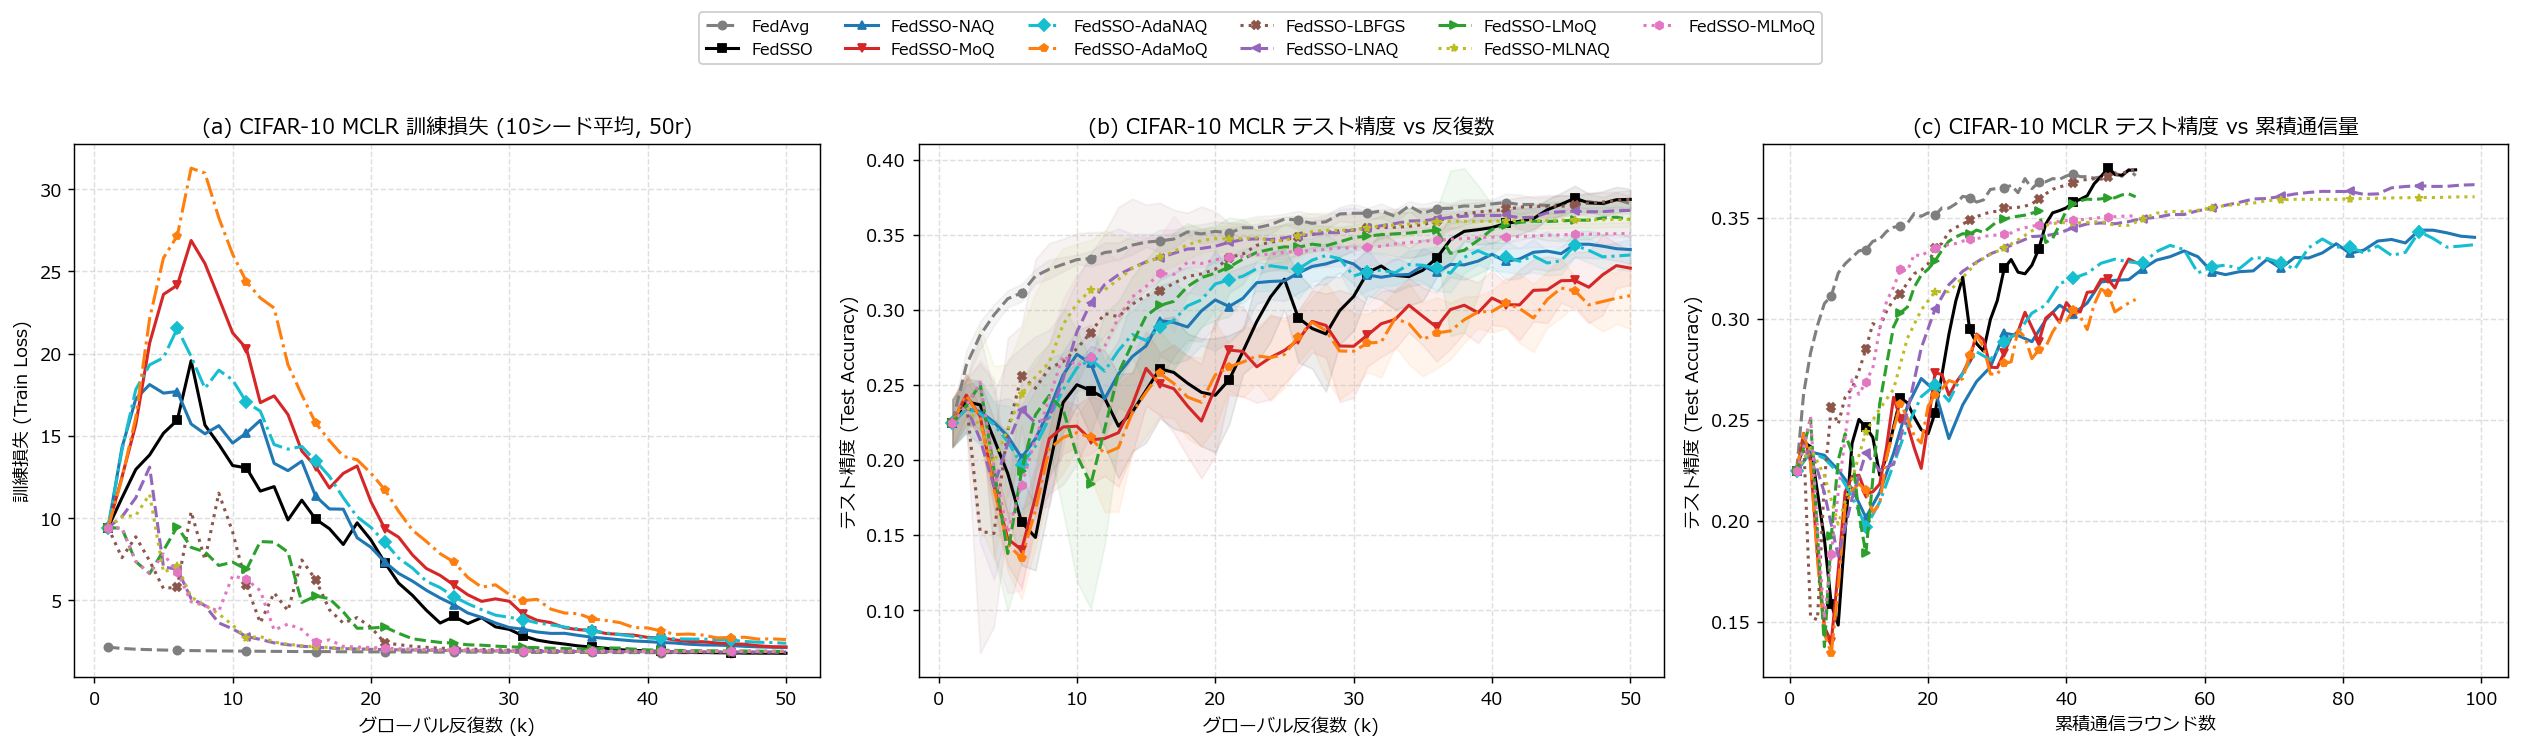

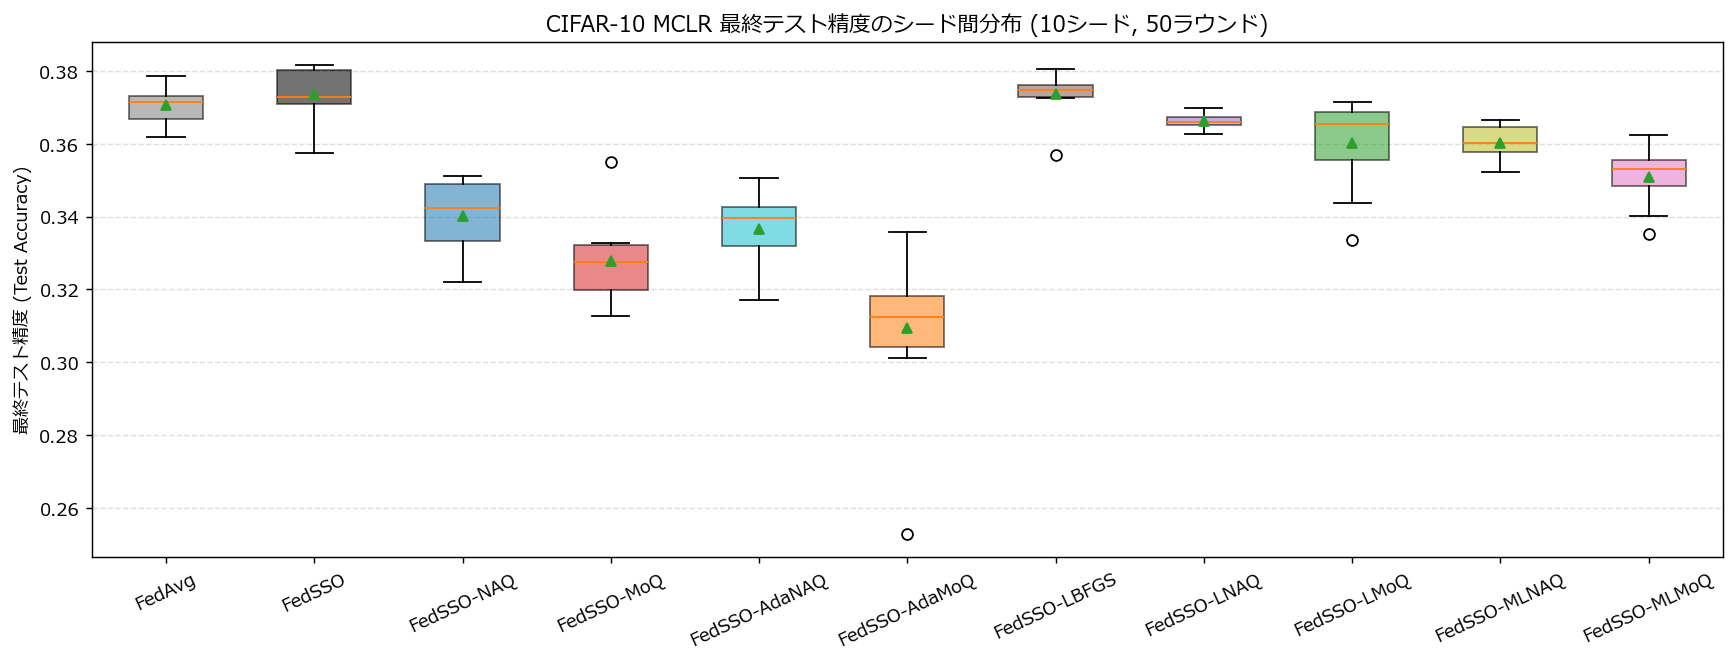

In [4]:
os.makedirs("../report/img", exist_ok=True)
plot_cifar10_mclr_curves(curves_dict, save_path="../report/img/ex007_cifar10_mclr_curves.png")
plot_cifar10_mclr_boxplot(per_seed_df, save_path="../report/img/ex007_cifar10_mclr_boxplot.png")

## 特定のシード値・アルゴリズムに絞ったグラフ表示

保存済みの全履歴 CSV（`../datasets/ex007_cifar10_mclr_history.csv`）から任意のアルゴリズム・シード値だけを指定して再描画できます。 `SELECTED_SEEDS = None` のときは全シード平均のみを自動表示・出力します。

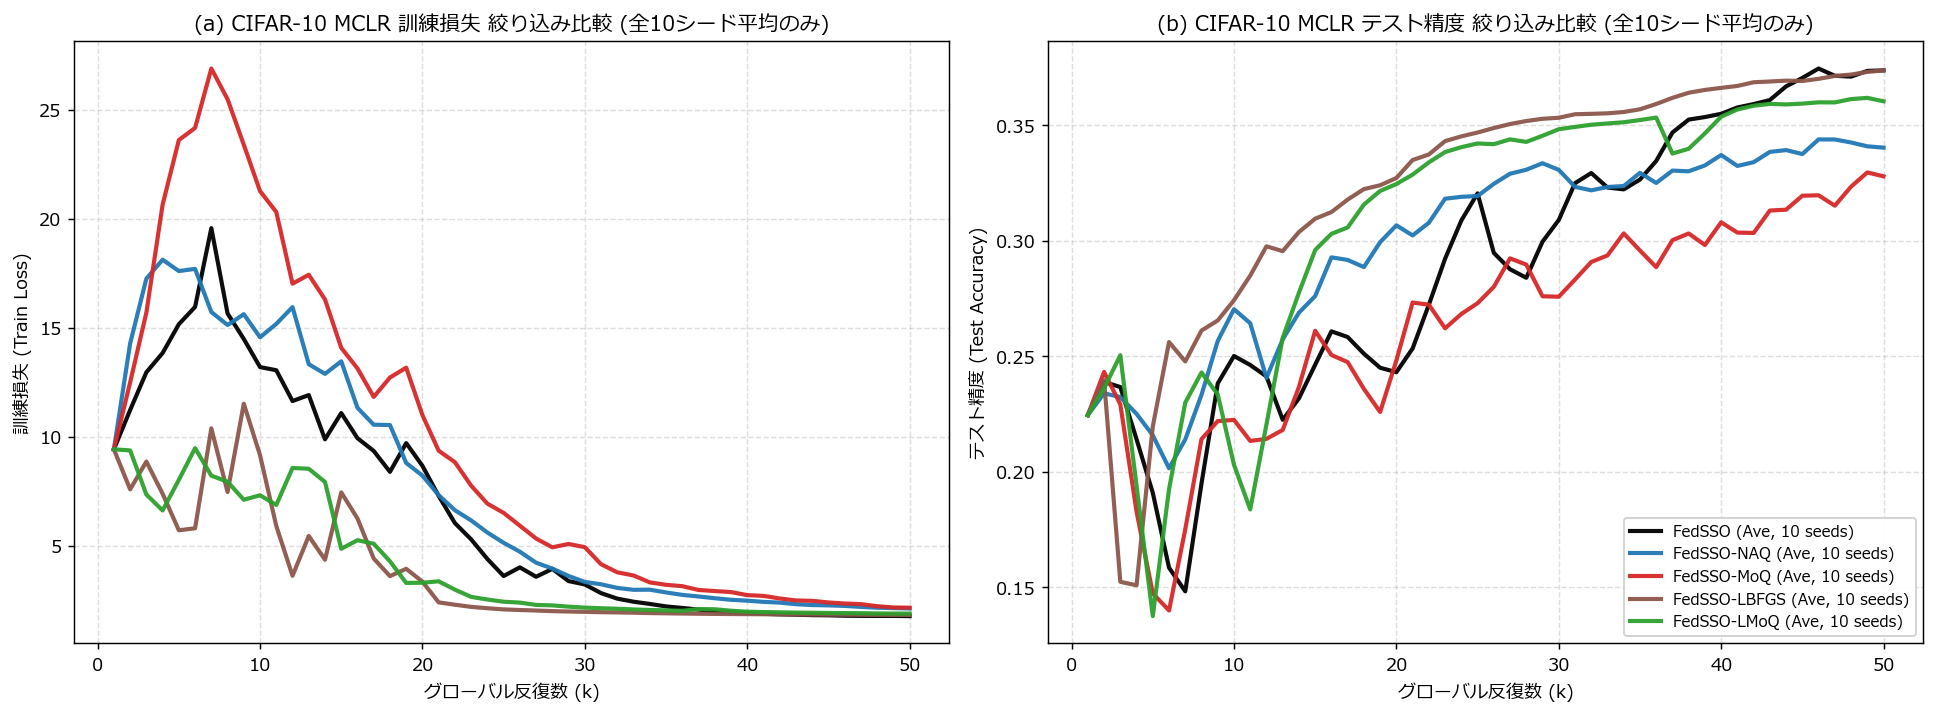

,Algorithm,Seeds,Round,Comm_Round,Train_Loss_Ave,Test_Acc_Ave
0,FedSSO,10,50,50.0,1.769582,0.373614
1,FedSSO-NAQ,10,50,99.0,2.120068,0.340209
2,FedSSO-MoQ,10,50,50.0,2.156296,0.327799
3,FedSSO-LBFGS,10,50,50.0,1.823583,0.373594
4,FedSSO-LMoQ,10,50,50.0,1.885566,0.360251


In [5]:
# ここを変更して特定のシード値・アルゴリズムのグラフを表示
# 利用可能なアルゴリズム:
#   ["FedAvg", "FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-AdaNAQ", "FedSSO-AdaMoQ",
#    "FedSSO-LBFGS", "FedSSO-LNAQ", "FedSSO-LMoQ", "FedSSO-MLNAQ", "FedSSO-MLMoQ"]
#   None を指定すると全手法が対象になります
# 利用可能なシード値: [42, 43, 44, 45, 46, 47, 48, 49, 50, 51] (None で全シード対象)
SELECTED_ALGOS = ["FedSSO", "FedSSO-NAQ", "FedSSO-MoQ", "FedSSO-LBFGS", "FedSSO-LMoQ"]
SELECTED_SEEDS = None       # None で全10シード対象（例: [42, 46] で特定シードに絞り込み）
X_AXIS_MODE = "round"       # "round" (反復数) または "comm" (累積通信ラウンド数)
SHOW_MEAN_CURVE = True      # 複数シード指定時に平均太線を重ね描きするか
PLOT_MEAN_ONLY = "auto"     # "auto": SELECTED_SEEDS=None 時に平均線のみ描画 / True: 平均のみ / False: 個別シードも描画
TABLE_MEAN_ONLY = "auto"    # "auto": SELECTED_SEEDS=None 時に平均のみの行を出力 / True: 平均のみ / False: シード別に出力

filtered_df = plot_filtered_results(
    selected_algos=SELECTED_ALGOS,
    selected_seeds=SELECTED_SEEDS,
    history_csv_path="../datasets/ex007_cifar10_mclr_history.csv",
    log_dir="../datasets/ex007_cifar10_mclr_logs",
    x_axis=X_AXIS_MODE,
    show_mean=SHOW_MEAN_CURVE,
    plot_mean_only=PLOT_MEAN_ONLY,
    table_mean_only=TABLE_MEAN_ONLY,
)
filtered_df